# 🏛️ Local Government Financial Sustainability: ML for Council Oversight

**Author:** Dean Wang | Lead Data & AI Engineer

**Government:** State Offices of Local Government, Auditor-General offices, ALGA, Productivity Commission

Dataset: sklearn synthetic — NO dataset needed.

---

Generated: (2200, 13)


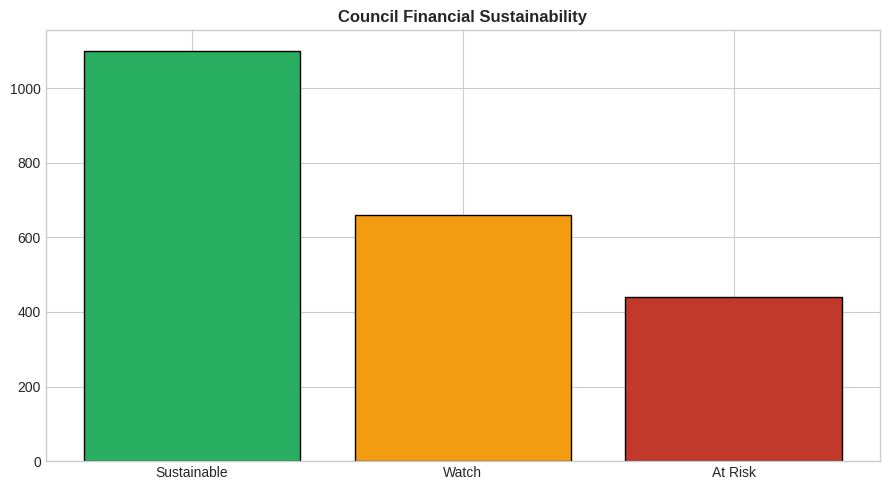

AU: 537 councils. Rural councils face $30B+ infrastructure backlog. Rate capping limits revenue in NSW/Vic.


In [1]:
import warnings,time,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,classification_report,cohen_kappa_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore');plt.style.use('seaborn-v0_8-whitegrid')
X_arr,y=make_classification(n_samples=2200,n_features=12,n_informative=9,n_classes=3,n_clusters_per_class=1,weights=[0.5,0.3,0.2],random_state=236)
names=['operating_ratio','own_source_revenue_pct','asset_renewal_ratio','infrastructure_backlog_pct','rate_base_growth','population_change_5yr','grant_dependency_pct','debt_service_ratio','cash_expense_cover_months','disaster_recovery_exposure','staff_vacancy_rate','asset_maintenance_gap']
df=pd.DataFrame(X_arr,columns=names);df['sustainability']=y;tc='sustainability'
tl=['Sustainable','Watch','At Risk'];nc=3
print(f"Generated: {df.shape}");colors=['#27ae60','#f39c12','#c0392b']
fig,ax=plt.subplots(figsize=(9,5));vc=df[tc].value_counts().sort_index()
ax.bar(range(nc),vc.values,color=colors,edgecolor='black');ax.set_xticks(range(nc));ax.set_xticklabels(tl)
ax.set_title('Council Financial Sustainability',fontweight='bold');plt.tight_layout();plt.savefig('t.png',dpi=150);plt.show()
print("AU: 537 councils. Rural councils face $30B+ infrastructure backlog. Rate capping limits revenue in NSW/Vic.")

LogReg: Acc=0.8982 F1=0.8976 Kappa=0.8344
RF: Acc=0.9418 F1=0.9416 Kappa=0.9054
XGB: Acc=0.9436 F1=0.9435 Kappa=0.9086
LGBM: Acc=0.9491 F1=0.9489 Kappa=0.9174
Best: LGBM


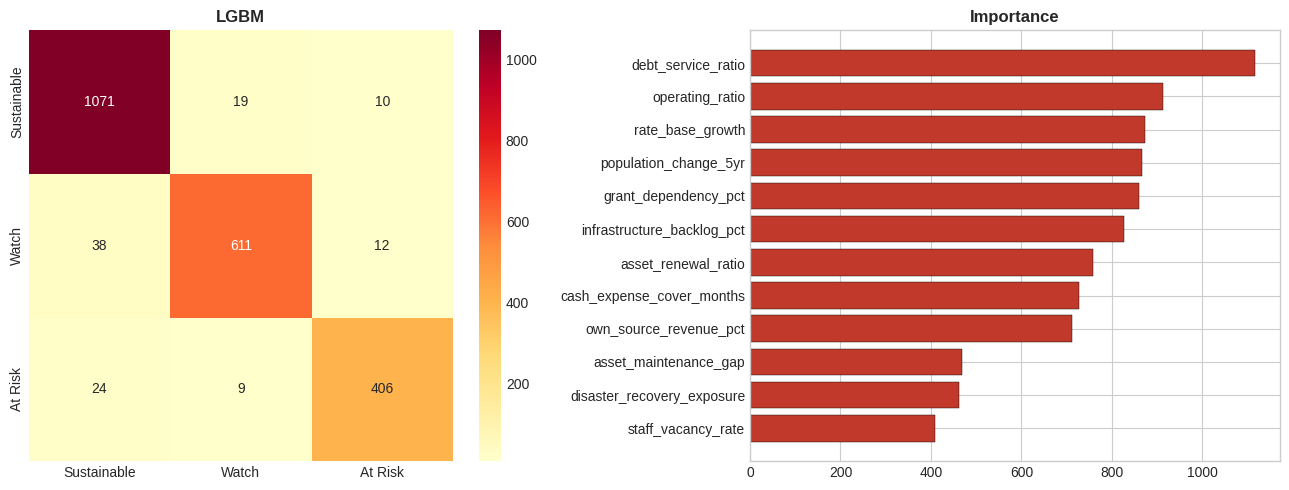

              precision    recall  f1-score   support

 Sustainable       0.95      0.97      0.96      1100
       Watch       0.96      0.92      0.94       661
     At Risk       0.95      0.92      0.94       439

    accuracy                           0.95      2200
   macro avg       0.95      0.94      0.95      2200
weighted avg       0.95      0.95      0.95      2200

DEPLOYMENT: LGBM F1=0.9489 Kappa=0.9174 | Annual financial statements -> early intervention & grant targeting


In [2]:
nums=[c2 for c2 in df.columns if c2!=tc];X=df[nums];y2=df[tc].values
try:
    from xgboost import XGBClassifier
except: XGBClassifier=None
try:
    from lightgbm import LGBMClassifier
except: LGBMClassifier=None
models={'LogReg':LogisticRegression(max_iter=2000,random_state=42,multi_class='multinomial'),'RF':RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)}
if XGBClassifier: models['XGB']=XGBClassifier(n_estimators=100,random_state=42,eval_metric='mlogloss',use_label_encoder=False,verbosity=0,n_jobs=-1)
if LGBMClassifier: models['LGBM']=LGBMClassifier(n_estimators=100,random_state=42,verbose=-1,n_jobs=-1,force_col_wise=True)
skf=StratifiedKFold(3,shuffle=True,random_state=42);Xa=X.values;results={}
for mn,mod in models.items():
    fa,ff,fk=[],[],[];fp=np.zeros(len(y2),dtype=int)
    for fi,(ti,vi) in enumerate(skf.split(Xa,y2)):
        m2=type(mod)(**mod.get_params());m2.fit(Xa[ti],y2[ti]);yp=m2.predict(Xa[vi]);fp[vi]=yp
        fa.append(accuracy_score(y2[vi],yp));ff.append(f1_score(y2[vi],yp,average='weighted'));fk.append(cohen_kappa_score(y2[vi],yp))
    results[mn]={'acc':np.mean(fa),'f1':np.mean(ff),'kappa':np.mean(fk),'preds':fp}
    print(f"{mn}: Acc={np.mean(fa):.4f} F1={np.mean(ff):.4f} Kappa={np.mean(fk):.4f}")
best=max(results,key=lambda k:results[k]['f1']);print(f"Best: {best}")
bp=results[best]['preds'];cm=confusion_matrix(y2,bp)
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='YlOrRd',xticklabels=tl,yticklabels=tl,ax=axes[0]);axes[0].set_title(f'{best}',fontweight='bold')
tm={k:v for k,v in models.items() if k!='LogReg'}
if tm:
    bt=max(tm,key=lambda m4:results[m4]['f1']);fm2=type(models[bt])(**models[bt].get_params());fm2.fit(Xa,y2)
    fi=pd.DataFrame({'Feature':X.columns,'Imp':fm2.feature_importances_}).sort_values('Imp')
    axes[1].barh(fi['Feature'],fi['Imp'],color='#c0392b',edgecolor='black',linewidth=0.3);axes[1].set_title('Importance',fontweight='bold')
plt.tight_layout();plt.savefig('r.png',dpi=150);plt.show()
print(classification_report(y2,bp,target_names=tl))
br=results[best];print(f"DEPLOYMENT: {best} F1={br['f1']:.4f} Kappa={br['kappa']:.4f} | Annual financial statements -> early intervention & grant targeting")